# 12-Month Trend Rule on Five Commodity ETFs (prototype)

**Rule.** At each month-end, look at the trailing 12-month return of GLD, SLV, USO, UNG and DBA. If it is positive, hold that ETF in its 20% slot for the next month; otherwise hold cash in that slot.
**Baseline.** Equal-weight (20% each) buy-and-hold, rebalanced monthly, same cost model.
**Protocol.** Build on 2008-2017, lock the rules, run once on 2018-now.

## Economics
Commodity supply reacts slowly: a mine, a well or a crop takes months to years to bring online. Shortages and gluts therefore persist, and prices tend to keep moving in the same direction for a while. A trend rule tries to ride those persistent moves and step aside during long declines. This is the time-series momentum effect documented by Moskowitz, Ooi and Pedersen (2012). Because we trade ETFs, futures roll costs (contango) are already inside the USO, UNG and DBA prices.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import trend

pd.options.display.float_format = "{:.3f}".format
plt.rcParams["figure.figsize"] = (10, 4)

TICKERS = trend.TICKERS
# Use only complete months: download up to the first day of the current month.
END = pd.Timestamp.today().normalize().replace(day=1)
prices = trend.load_prices(TICKERS, start="2007-01-01", end=END)
prices.apply(lambda s: s.first_valid_index()).rename("first date").to_frame()

,first date
GLD,2007-01-03
SLV,2007-01-03
USO,2007-01-03
UNG,2007-04-18
DBA,2007-01-05


Data are Yahoo Finance adjusted closes (distributions included), starting January 2007 so the first 12-month signal is available in early 2008. UNG starts in April 2007, so its first signal is in April 2008 and it sits in cash before that. Prices are cached to `data/prices.csv`; call `load_prices(..., refresh=True)` to re-download.

## 1. Build window: 2008-2017
Everything in this section uses prices **up to 2017-12-31 only**.

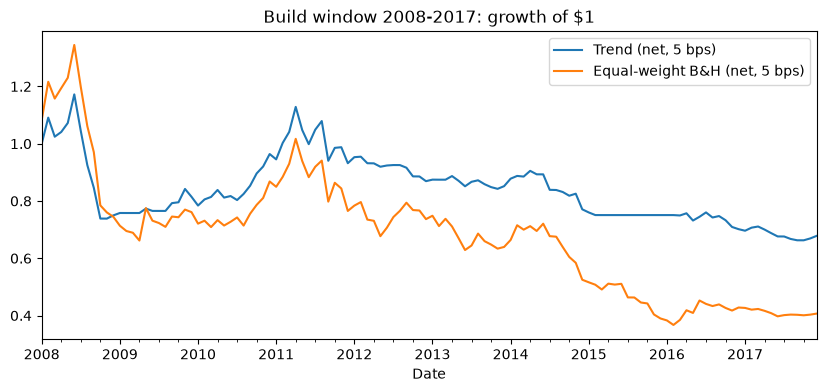

,Ann. return,Ann. vol,Sharpe,Max DD,Turnover / yr
Trend,-0.038,0.125,-0.247,-0.435,1.864
Buy & hold,-0.086,0.187,-0.384,-0.727,0.598


In [2]:
BUILD_START, BUILD_END = "2008-01-01", "2017-12-31"
build_px = prices.loc[:BUILD_END]

sig_b = trend.month_end_signals(build_px, lookback=12)
w_b = trend.strategy_weights(sig_b)
strat_b = trend.backtest(build_px, w_b, cost_bps=5).loc[BUILD_START:]
base_b = trend.buy_and_hold_ew(build_px, cost_bps=5).loc[BUILD_START:]

def wealth(r):
    return (1 + r).cumprod()

ax = wealth(strat_b["net"]).plot(label="Trend (net, 5 bps)")
wealth(base_b["net"]).plot(ax=ax, label="Equal-weight B&H (net, 5 bps)")
ax.set_title("Build window 2008-2017: growth of $1"); ax.legend(); plt.show()

pd.DataFrame({"Trend": trend.metrics(strat_b), "Buy & hold": trend.metrics(base_b)}).T

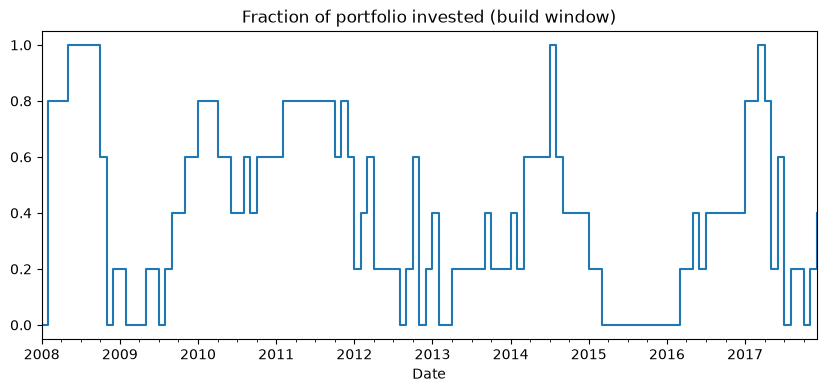

In [3]:
# Fraction of the portfolio invested each month in the build window
ax = w_b.loc[BUILD_START:BUILD_END].sum(axis=1).plot(drawstyle="steps-post")
ax.set_ylim(-0.05, 1.05); ax.set_title("Fraction of portfolio invested (build window)"); plt.show()

### Robustness peek (not tuning)
We do not pick the lookback from this table; 12 months is fixed by the idea doc. This only checks that the result is not a knife-edge on that one parameter.

In [4]:
peek = {}
for lb in (6, 9, 12):
    w_lb = trend.strategy_weights(trend.month_end_signals(build_px, lookback=lb))
    peek[f"{lb}m"] = trend.metrics(trend.backtest(build_px, w_lb, cost_bps=5).loc[BUILD_START:])
pd.DataFrame(peek).T

,Ann. return,Ann. vol,Sharpe,Max DD,Turnover / yr
6m,0.008,0.120,0.123,-0.296,1.990
9m,-0.019,0.117,-0.105,-0.372,1.937
12m,-0.038,0.125,-0.247,-0.435,1.864


## 2. Lock the rules
**Locked on the build window. No edits below this line.**

| Parameter | Value |
|---|---|
| Universe | GLD, SLV, USO, UNG, DBA |
| Lookback | 12 months, trailing total return > 0 |
| Weights | 20% per ETF when on, else that 20% in cash |
| Rebalance | Month-end signal, applied to next month |
| Cash return | 0% (simplification; BIL would add a small positive return) |
| Costs | 5 bps x turnover (sensitivity at 10 and 20 bps) |

In [5]:
LOOKBACK, COST_BPS, CASH_RETURN = 12, 5.0, 0.0
OOS_START = "2018-01-01"

## 3. Held-out run: 2018-now (executed once)
This is the only cell that evaluates 2018+ data. Signals use the full price history, so the January 2018 position comes from the December 2017 signal.

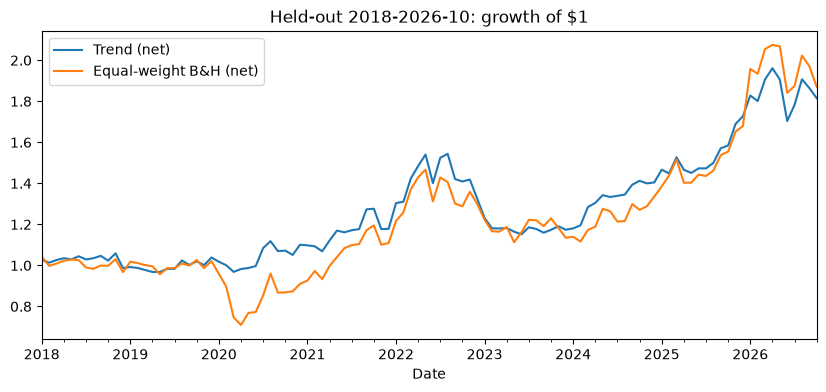

In [6]:
sig = trend.month_end_signals(prices, lookback=LOOKBACK)
w = trend.strategy_weights(sig)
strat_all = trend.backtest(prices, w, cost_bps=COST_BPS, cash_return=CASH_RETURN)
base_all = trend.buy_and_hold_ew(prices, cost_bps=COST_BPS, cash_return=CASH_RETURN)
strat_oos, base_oos = strat_all.loc[OOS_START:], base_all.loc[OOS_START:]

ax = wealth(strat_oos["net"]).plot(label="Trend (net)")
wealth(base_oos["net"]).plot(ax=ax, label="Equal-weight B&H (net)")
ax.set_title(f"Held-out 2018-{strat_oos.index[-1]:%Y-%m}: growth of $1"); ax.legend(); plt.show()

## 4. Results: in-sample vs out-of-sample (net of 5 bps)

In [7]:
results = pd.DataFrame({
    ("2008-2017", "Trend"): trend.metrics(strat_b),
    ("2008-2017", "Buy & hold"): trend.metrics(base_b),
    ("2018-now", "Trend"): trend.metrics(strat_oos),
    ("2018-now", "Buy & hold"): trend.metrics(base_oos),
}).T
results

Ann. return  Ann. vol  Sharpe  Max DD  Turnover / yr
2008-2017 Trend            -0.038     0.125  -0.247  -0.435          1.864
          Buy & hold       -0.086     0.187  -0.384  -0.727          0.598
2018-now  Trend             0.070     0.131   0.581  -0.254          1.559
          Buy & hold        0.073     0.179   0.486  -0.320          0.749

## 5. Transaction-cost sensitivity (out-of-sample)

In [8]:
rows = {}
for bps in (5, 10, 20):
    s = trend.backtest(prices, w, cost_bps=bps).loc[OOS_START:]
    b = trend.buy_and_hold_ew(prices, cost_bps=bps).loc[OOS_START:]
    rows[(bps, "Trend")] = trend.metrics(s)
    rows[(bps, "Buy & hold")] = trend.metrics(b)
costs = pd.DataFrame(rows).T
costs.index.names = ["cost (bps)", "portfolio"]
costs[["Ann. return", "Sharpe", "Turnover / yr"]]

Ann. return  Sharpe  Turnover / yr
cost (bps) portfolio                                     
5          Trend             0.070   0.581          1.559
           Buy & hold        0.073   0.486          0.749
10         Trend             0.069   0.575          1.559
           Buy & hold        0.073   0.484          0.749
20         Trend             0.067   0.563          1.559
           Buy & hold        0.072   0.480          0.749

## 6. Drawdowns and per-ETF contribution

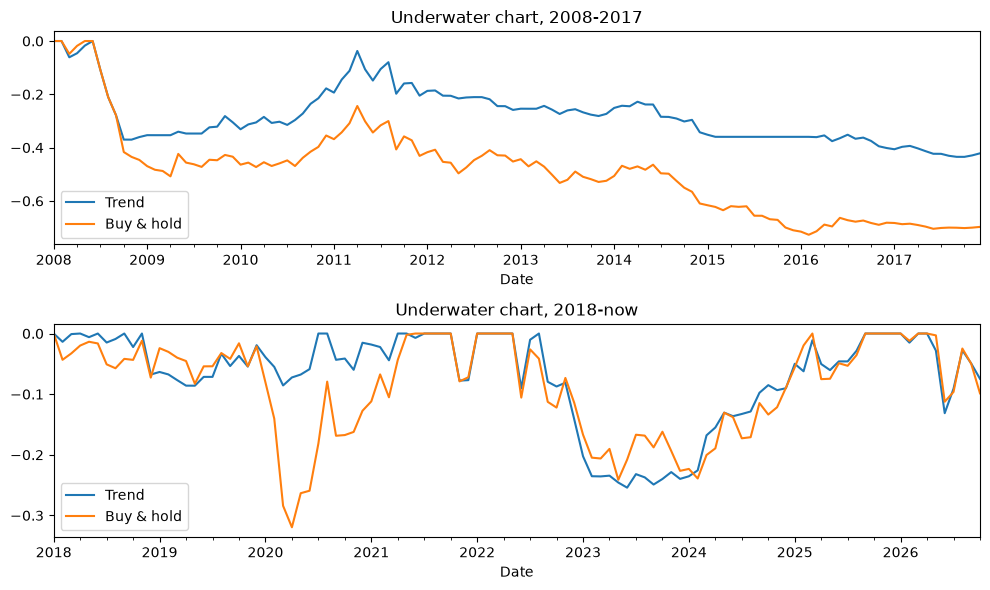

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, (name, s, b) in zip(axes, [("2008-2017", strat_b, base_b), ("2018-now", strat_oos, base_oos)]):
    trend.drawdown(s["net"]).plot(ax=ax, label="Trend")
    trend.drawdown(b["net"]).plot(ax=ax, label="Buy & hold")
    ax.set_title(f"Underwater chart, {name}"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

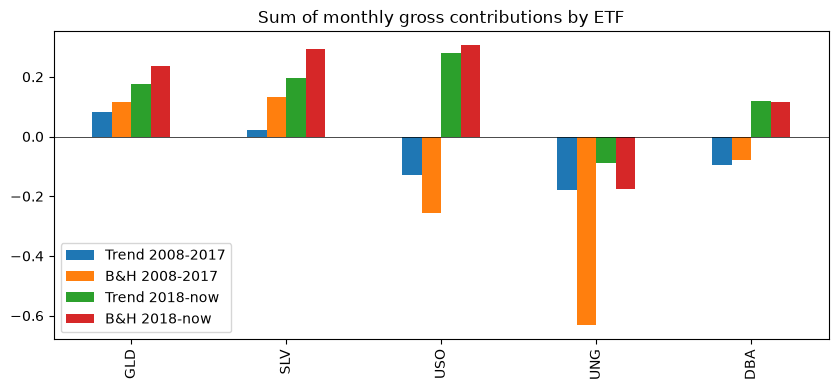

,Trend 2008-2017,B&H 2008-2017,Trend 2018-now,B&H 2018-now
GLD,0.082,0.117,0.175,0.235
SLV,0.023,0.134,0.197,0.294
USO,-0.130,-0.257,0.279,0.306
UNG,-0.179,-0.632,-0.090,-0.177
DBA,-0.094,-0.078,0.119,0.114


In [10]:
ew = trend.equal_weights(prices)
contrib = pd.DataFrame({
    "Trend 2008-2017": trend.contributions(prices, w).loc[BUILD_START:BUILD_END].sum(),
    "B&H 2008-2017": trend.contributions(prices, ew).loc[BUILD_START:BUILD_END].sum(),
    "Trend 2018-now": trend.contributions(prices, w).loc[OOS_START:].sum(),
    "B&H 2018-now": trend.contributions(prices, ew).loc[OOS_START:].sum(),
})
ax = contrib.plot.bar(title="Sum of monthly gross contributions by ETF"); ax.axhline(0, color="k", lw=0.5); plt.show()
contrib

### Spot check
One ETF-month traced by hand: the signal at the end of month *t-1*, the weight held in month *t*, and the ETF's return in month *t*.

In [11]:
me = trend.month_end_prices(prices)
t, prev, tk = pd.Timestamp("2020-04-30"), pd.Timestamp("2020-03-31"), "USO"
yr_ago = prev - pd.offsets.MonthEnd(12)
r12 = me.loc[prev, tk] / me.loc[yr_ago, tk] - 1
print(f"{tk} 12m return {yr_ago:%Y-%m} -> {prev:%Y-%m}: {r12:.1%} -> signal {sig.loc[prev, tk]}")
print(f"weight held in {t:%Y-%m}: {w.loc[t, tk]:.2f}")
print(f"{tk} return in {t:%Y-%m}: {me.loc[t, tk] / me.loc[prev, tk] - 1:.1%}")
print(f"strategy contribution from {tk} in {t:%Y-%m}: {trend.contributions(prices, w).loc[t, tk]:.2%}")

USO 12m return 2019-03 -> 2020-03: -66.3% -> signal 0
weight held in 2020-04: 0.00
USO return in 2020-04: -43.2%
strategy contribution from USO in 2020-04: -0.00%


## 7. Limitations
- **Five assets.** Results are noisy and driven by a handful of episodes (2008, the 2014-15 oil collapse, 2020, 2022).
- **Trend following was weak for much of the 2010s.** Expect smaller drawdowns more than higher returns.
- **ETF roll cost is embedded** in USO, UNG and DBA. UNG in particular has lost most of its value to contango, which a trend rule partly avoids by staying in cash during long declines. This is part of the result, not separate from it.
- **Cash at 0%.** Understates the strategy in 2018-19 and 2022+ when T-bill yields were meaningful. Swapping in BIL is a one-line change (`cash_return`).
- **Simple cost model.** A flat bps charge on turnover; no bid-ask modeling, market impact or taxes.
- **Monthly granularity.** Intramonth drawdowns are not captured.